
Представим кото-шоу, где участник любопытный котик. Перед котиком стоят коробки.
 В одной из коробок вкуснейшая рыбка.
 В двух других коробках пусто.

Игра проходит в три этапа
1. Котик наугад выбирает одну коробку 
2. Ведущий шоу  открывает одну из двух оставшихся коробок, в которой пусто*
3. Ведущий предлагает котику выбор: остаться при своем выборе или сменить решение

 Выгодно ли котику поменять выбор?

### Импорт библиотек для моделирования


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


### Функция симуляции одного раунда игры с котиком


In [4]:
def play_round(switch=True):
    prize = np.random.randint(0, 3)
    choice = np.random.randint(0, 3)
    if switch:
        return choice != prize
    return choice == prize


Проверим результат для нескольких одиночных игр:


In [9]:
for i in range(10):
    print("Игра", i + 1, " Без смены", play_round(False), " Со сменой", play_round(True))


Игра 1  Без смены False  Со сменой True
Игра 2  Без смены False  Со сменой False
Игра 3  Без смены False  Со сменой True
Игра 4  Без смены False  Со сменой True
Игра 5  Без смены False  Со сменой False
Игра 6  Без смены False  Со сменой True
Игра 7  Без смены False  Со сменой False
Игра 8  Без смены False  Со сменой True
Игра 9  Без смены False  Со сменой False
Игра 10  Без смены False  Со сменой True



Смоделируем 10 000 игр для обеих стратегий поведения котика


In [10]:
n = 10000
prizes = np.random.randint(0, 3, size=n)
choices = np.random.randint(0, 3, size=n)

s1 = (choices == prizes)
s2 = (choices != prizes)

s1win = np.mean(s1)
s2win = np.mean(s2)

print("Доля побед котика без смены коробки", s1win)
print("Доля побед котика при смене коробки ", s2win)


Доля побед котика без смены коробки 0.3345
Доля побед котика при смене коробки  0.6655


Сведем полученные результаты в сравнительную таблицу:


In [13]:
df_res = pd.DataFrame({
    'Стратегия котика': ['Не менять коробку', 'Сменить коробку'],
    'Теоретическая вероятность': [1/3, 2/3],
    'Частота в симуляции': [s1win, s2win]
})
df_res


,Стратегия котика,Теоретическая вероятность,Частота в симуляции
0,Не менять коробку,0.333333,0.3345
1,Сменить коробку,0.666667,0.6655


### График сходимости относительной частоты побед


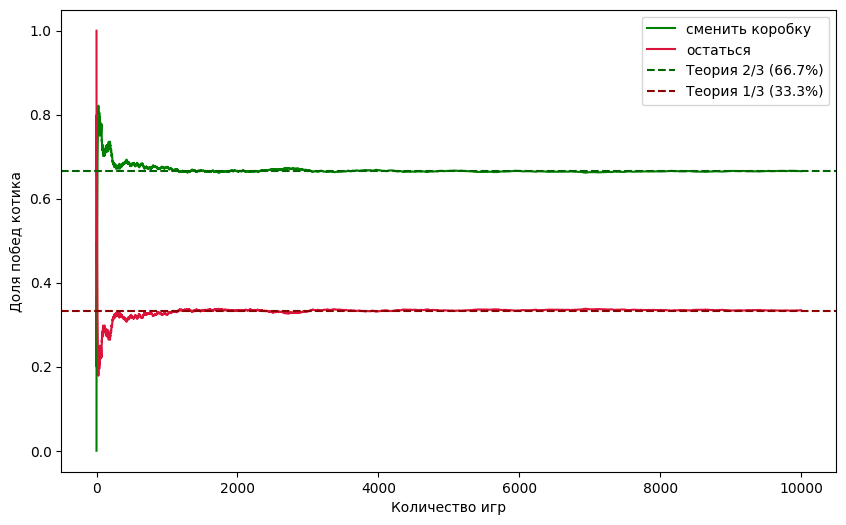

In [14]:
s11 = np.cumsum(s1) / np.arange(1, n + 1)
s22 = np.cumsum(s2) / np.arange(1, n + 1)

plt.figure(figsize=(10, 6))
plt.plot(s22, label='сменить коробку', color='green')
plt.plot(s11, label='остаться', color='crimson')
plt.axhline(2/3, color='darkgreen', linestyle='--',label='Теория 2/3 (66.7%)')
plt.axhline(1/3, color='darkred', linestyle='--', label='Теория 1/3 (33.3%)')
plt.xlabel('Количество игр')
plt.ylabel('Доля побед котика')
plt.legend()
plt.show()


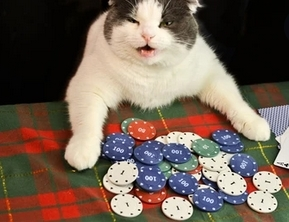

In [3]:
from IPython.display import Image
Image(filename='cats4.jpg')